# 05 -- Statistical Insight: Modelado Predictivo de Transicion de Regimen Demografico (2023 -> 2050)

**Pregunta central de investigacion:**
> *¿Hacia que regimen demografico transitaran las naciones del mundo hacia mediados de siglo (2050), que factores estructurales del presente determinan el salto cualitativo hacia la Post-Transicion, y que paises enfrentan un riesgo critico de quedar atrapados en la Pre-Transicion?*

**Articulacion con el EDA Multivariado (Notebook 04):**
En el Notebook 04 construimos el **Indice Compuesto Demografico (ICD)** (0–100) y segmentamos la heterogeneidad global en **cuatro regimenes demograficos** (*1. Pre-Transicional*, *2. Transicion Media*, *3. Post-Transicion* y *4. Dinamica Migratoria*). Asimismo, comprobamos que unicamente la esperanza de vida converge, mientras que la fecundidad y la estructura de edades divergen.

El presente notebook traslada estos insumos a un **pipeline completo de Machine Learning supervisado**:
1. **Construccion del Target:** Proyeccion de los datos oficiales de Naciones Unidas (WPP 2024 Medium) al horizonte 2050 dentro del espacio factorial multivariado para determinar el regimen destino $\text{Regimen}_{2050}$.
2. **Curaduria de Features:** Evaluacion del `ICD_2023` y los 7 pilares demograficos como espacio de entrada.
3. **Benchmarking de Clasificadores:** Comparativa exhaustiva bajo validacion cruzada estratificada (5-Fold CV) entre 5 familias algoritmicas: *Multinomial Logistic Regression*, *Random Forest*, *Hist Gradient Boosting*, *Support Vector Machine (RBF)* y *K-Nearest Neighbors*.
4. **Diagnostico y Explicabilidad:** Evaluacion de matrices de confusion e importancia relativa de variables (Gini / MDI), demostrando el rol conductor del ICD.
5. **Inferencia y Respuestas Demograficas:** Estimacion de probabilidades condicionales $P(\text{Regimen}_{2050} = k \mid \mathbf{x}_{2023})$, identificando el umbral critico del ICD, los paises graduados a la post-transicion y las naciones en trampa de estancamiento.

---


## 5.1 Setup y Carga de Insumos (Silver y Gold)
Cargamos las estimaciones observadas (Silver), las proyecciones oficiales 2050 (Silver) y los artefactos generados en el Notebook 04: el `ICD` (Gold), los scores factoriales y la matriz de loadings.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

sys.path.insert(0, str(Path.cwd().parent))
from src.config import SILVER, GOLD, BRONZE, FIGURES_FINAL, FIGURES_EDA, SEED
from src.viz import setup_style, save_figure

setup_style()
np.random.seed(SEED)

# 1. Cargar datos Silver y Gold
df_hist = pd.read_parquet(SILVER / 'wpp2024_countries_estimates.parquet')
df_proj = pd.read_parquet(SILVER / 'wpp2024_countries_projections.parquet')
df_icd_2023 = pd.read_parquet(GOLD / 'demographic_index.parquet')
df_pca = pd.read_parquet(GOLD / 'pca_scores.parquet')
df_loadings = pd.read_parquet(GOLD / 'pca_loadings.parquet')

# 2. Mapeo de continentes
region_map = {
    910: 'Africa', 911: 'Africa', 912: 'Africa', 913: 'Africa', 914: 'Africa',
    5500: 'Asia', 906: 'Asia', 5501: 'Asia', 920: 'Asia', 922: 'Asia',
    923: 'Europe', 924: 'Europe', 925: 'Europe', 926: 'Europe',
    915: 'Latin America & Caribbean', 916: 'Latin America & Caribbean', 931: 'Latin America & Caribbean',
    918: 'Northern America',
    927: 'Oceania', 928: 'Oceania', 954: 'Oceania', 957: 'Oceania'
}
df_hist['Continent'] = df_hist['ParentID'].map(region_map)
df_proj['Continent'] = df_proj['ParentID'].map(region_map)

INDEX_VARS = ['TFR', 'LEx', 'IMR', 'PopGrowthRate', 'MedianAgePop', 'CNMR', 'GenderGapLE']
FEATURE_COLS = ['log_TFR', 'LEx', 'log_IMR', 'PopGrowthRate', 'MedianAgePop', 'CNMR', 'GenderGapLE']

print(f'Historico (Silver): {df_hist.shape[0]:,} filas')
print(f'Proyecciones (Silver): {df_proj.shape[0]:,} filas')
print(f'Paises con ICD y Regimenes (Gold): {df_pca["Location"].nunique()} entidades')
print(f'Regimenes demograficos base (2023): {list(df_pca["Regime"].unique())}')


Historico (Silver): 17,538 filas
Proyecciones (Silver): 18,486 filas
Paises con ICD y Regimenes (Gold): 237 entidades
Regimenes demograficos base (2023): ['1. Pre-Transicional', '3. Post-Transicion', '4. Dinamica Migratoria', '2. Transicion Media']


## 5.2 Definicion del Problema Predictivo y Construccion del Target (2050)

Para entrenar un modelo supervisado de transicion demografica, necesitamos establecer el **regimen destino al anio 2050** de cada pais.

### Metodologia de Asignacion de Clases Destino:
1. Tomamos las proyecciones oficiales de la variante central de la ONU (*WPP 2024 Medium*) en el anio **2050**.
2. Proyectamos las variables de cada pais en el **mismo espacio factorial (StandardScaler + PCA)** ajustado en el Notebook 04 con los datos de 2023.
3. Asignamos cada observacion proyectada de 2050 al **centroide de cluster de K-Means** correspondiente del corte 2023.
4. Construimos la **Matriz de Transicion Empirica** ($2023 \to 2050$) como punto de partida demografico.


  Saved: outputs\figures\final\05_empirical_transition_matrix.png


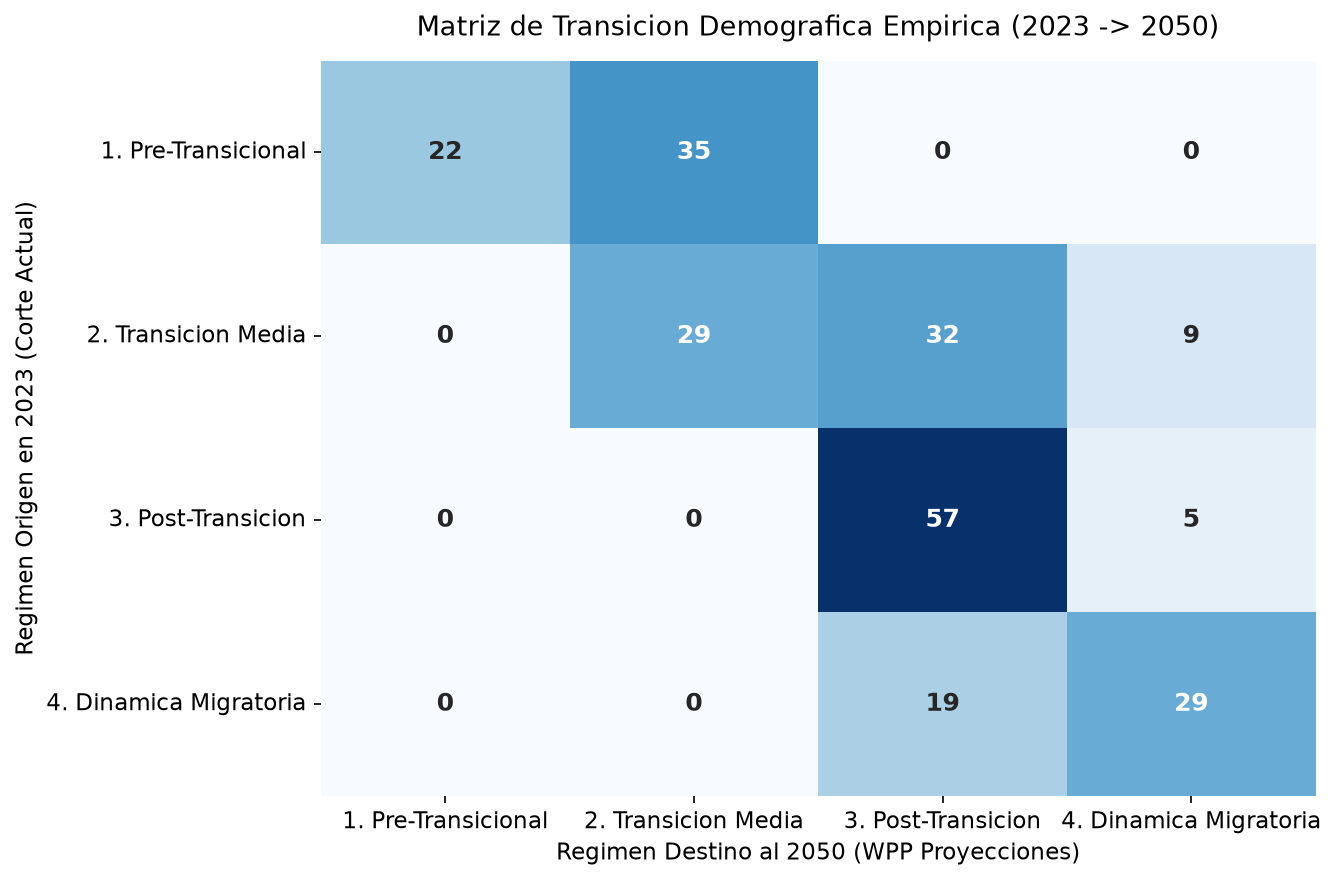

Distribucion de Regimenes:
                        Conteo 2023  Conteo 2050
1. Pre-Transicional              57           22
2. Transicion Media              70           64
3. Post-Transicion               62          108
4. Dinamica Migratoria           48           43


In [2]:
# 1. Reconstruccion del espacio factorial y centroides 2023 (Notebook 04)
df_2023 = df_hist[df_hist['Time'] == 2023].dropna(subset=INDEX_VARS).copy()
df_2023['log_TFR'] = np.log(df_2023['TFR'])
df_2023['log_IMR'] = np.log(df_2023['IMR'] + 1)

scaler_2023 = StandardScaler()
X_scaled_2023 = scaler_2023.fit_transform(df_2023[FEATURE_COLS])
pca_2023 = PCA(random_state=SEED)
scores_2023 = pca_2023.fit_transform(X_scaled_2023)

km_2023 = KMeans(n_clusters=4, random_state=SEED, n_init=20)
clusters_raw_2023 = km_2023.fit_predict(scores_2023[:, :2])
df_2023['ClusterRaw'] = clusters_raw_2023

loc_to_regime = df_pca.set_index('Location')['Regime'].to_dict()
loc_to_icd = df_pca.set_index('Location')['ICD'].to_dict()
df_2023['Regime'] = df_2023['Location'].map(loc_to_regime)
raw_to_regime = df_2023.groupby('ClusterRaw')['Regime'].agg(lambda x: x.mode()[0]).to_dict()

# 2. Proyeccion del horizonte 2050 en el espacio factorial 2023
df_2050 = df_proj[df_proj['Time'] == 2050].dropna(subset=INDEX_VARS).copy()
df_2050['log_TFR'] = np.log(df_2050['TFR'])
df_2050['log_IMR'] = np.log(df_2050['IMR'] + 1)

X_scaled_2050 = scaler_2023.transform(df_2050[FEATURE_COLS])
scores_2050 = pca_2023.transform(X_scaled_2050)
clusters_raw_2050 = km_2023.predict(scores_2050[:, :2])
df_2050['Regime_2050'] = pd.Series(clusters_raw_2050, index=df_2050.index).map(raw_to_regime)
df_2050['Regime_2023'] = df_2050['Location'].map(loc_to_regime)

# 3. Matriz de Transicion Empirica (2023 -> 2050)
regime_order = ['1. Pre-Transicional', '2. Transicion Media', '3. Post-Transicion', '4. Dinamica Migratoria']
ct_transition = pd.crosstab(df_2050['Regime_2023'], df_2050['Regime_2050']).reindex(index=regime_order, columns=regime_order).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(ct_transition, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, annot_kws={'size': 12, 'weight': 'bold'})
ax.set_title('Matriz de Transicion Demografica Empirica (2023 -> 2050)', fontsize=13, pad=12)
ax.set_xlabel('Regimen Destino al 2050 (WPP Proyecciones)', fontsize=11)
ax.set_ylabel('Regimen Origen en 2023 (Corte Actual)', fontsize=11)
plt.tight_layout()
save_figure(fig, '05_empirical_transition_matrix', subdir='final')
plt.show()

print('Distribucion de Regimenes:')
print(pd.DataFrame({
    'Conteo 2023': df_2050['Regime_2023'].value_counts(),
    'Conteo 2050': df_2050['Regime_2050'].value_counts()
}).reindex(regime_order))


> **Interpretacion 5.2 -- Dinamica de la Matriz de Transicion 2023 -> 2050:**
> * **Avance masivo hacia la Post-Transicion:** La post-transicion se expande sustancialmente: pasa de 62 paises en 2023 a **108 paises en 2050**. Esto se explica por la entrada de 32 naciones provenientes de *Transicion Media* y 19 de *Dinamica Migratoria* que moderan sus flujos de entrada.
> * **Persistencia de la Trampa Pre-Transicional:** De los 57 paises pre-transicionales en 2023, **22 naciones permanecen atrapadas en la Pre-Transicion al 2050**. Ninguna logra dar un salto directo hacia la post-transicion sin pasar por etapas intermedias.
> * **Graduacion del bloque medio:** 32 paises (45.7%) de *Transicion Media* dan el salto exitoso a la *Post-Transicion*, consolidando la transicion demografica en Latinoamerica y Asia.


## 5.3 Curaduria e Ingenieria de Features (Espacio de Entrada 2023)

Construimos la matriz de diseño $X$ utilizando exclusivamente la informacion observada en el corte **2023**.  
El vector de caracteristicas de cada pais se define como:

$$\mathbf{x}_i = [\text{ICD}_i, \text{TFR}_i, \text{LEx}_i, \text{IMR}_i, \text{PopGrowthRate}_i, \text{MedianAgePop}_i, \text{CNMR}_i, \text{GenderGapLE}_i]$$

Examinamos las correlaciones y la capacidad de discriminacion del `ICD` frente a las variables individuales.


  Saved: outputs\figures\final\05_features_correlation_matrix.png


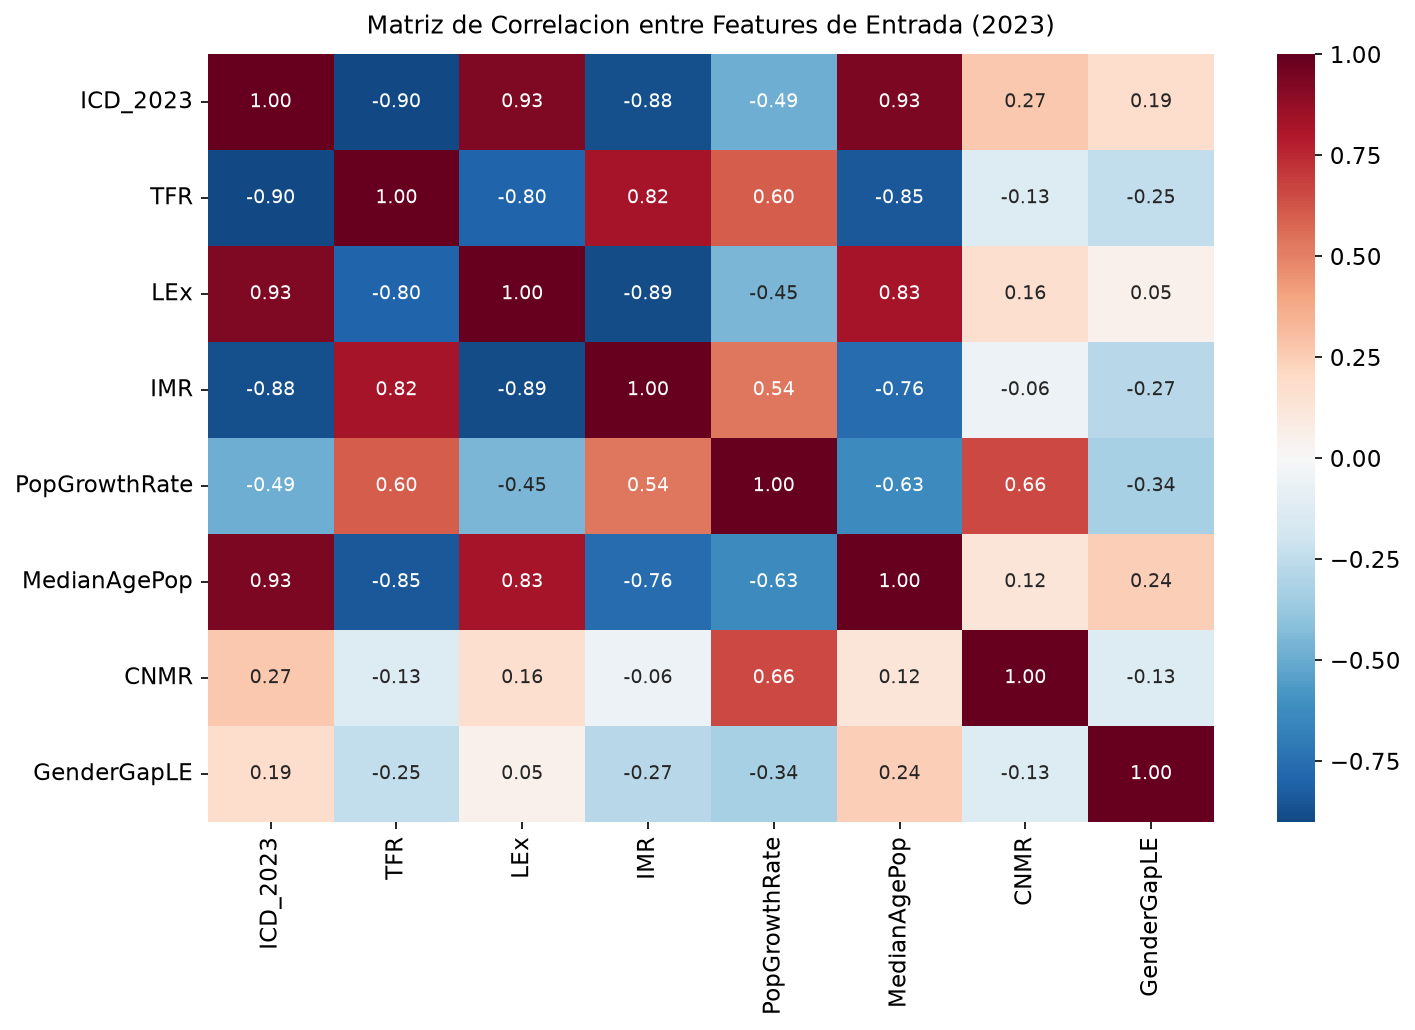

Muestra de entrenamiento: 237 paises/areas con 8 caracteristicas observadas en 2023
Distribucion de clases destino (y_2050):
1. Pre-Transicional        22
2. Transicion Media        64
3. Post-Transicion        108
4. Dinamica Migratoria     43
Name: count, dtype: int64


In [3]:
# Construccion del dataset unificado de entrenamiento
common_locs = sorted(list(set(df_2023['Location']).intersection(set(df_2050['Location']))))

df_ml = df_2023[df_2023['Location'].isin(common_locs)].sort_values('Location').copy()
df_target = df_2050[df_2050['Location'].isin(common_locs)].sort_values('Location').copy()

df_ml['ICD_2023'] = df_ml['Location'].map(loc_to_icd).values
df_ml['Target_Regime_2050'] = df_target['Regime_2050'].values

X_cols = ['ICD_2023', 'TFR', 'LEx', 'IMR', 'PopGrowthRate', 'MedianAgePop', 'CNMR', 'GenderGapLE']
X = df_ml[X_cols].to_numpy(dtype=float)
y = np.array(df_ml['Target_Regime_2050'].values, dtype=str)

# Matriz de correlaciones entre features en 2023
corr_mat = df_ml[X_cols].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, cbar=True, annot_kws={'size': 9})
ax.set_title('Matriz de Correlacion entre Features de Entrada (2023)', fontsize=12, pad=10)
plt.tight_layout()
save_figure(fig, '05_features_correlation_matrix', subdir='final')
plt.show()

print(f'Muestra de entrenamiento: {X.shape[0]} paises/areas con 8 caracteristicas observadas en 2023')
print('Distribucion de clases destino (y_2050):')
print(pd.Series(y).value_counts().reindex(regime_order))


## 5.4 Benchmarking y Evaluacion Comparativa de Clasificadores

Sometemos el problema a una evaluacion comparativa rigurosa entre **cinco familias algoritmicas representativas**:
1. **Multinomial Logistic Regression:** Modelo parametrico regularizado (L2), rapido y altamente interpretable.
2. **Random Forest Classifier:** Ensamble no parametrico basado en bagging, insensible a escalas y capaz de modelar relaciones no lineales complejas.
3. **Hist Gradient Boosting Classifier:** Ensamble secuencial basado en boosting de arboles, optimizado para gradientes en datos tabulares.
4. **Support Vector Machine (RBF Kernel):** Clasificador de margen maximo que proyecta los datos a un espacio de dimension superior.
5. **K-Nearest Neighbors (KNN):** Metodo no parametrico basado en vecindad euclidiana local ($k=5$).

### Esquema de Evaluacion:
- **Estratificacion:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)` para preservar la proporcion de clases en cada pliegue.
- **Estandarizacion:** Encapsulada dentro de un `Pipeline` para evitar cualquier fuga de datos (*data leakage*) en los pliegues de prueba.
- **Metricas:** *Accuracy*, *F1-Macro* (trata todas las clases equitativamente, clave ante desbalances) y *F1-Weighted*.


  Saved: outputs\figures\final\05_model_comparison_benchmark.png


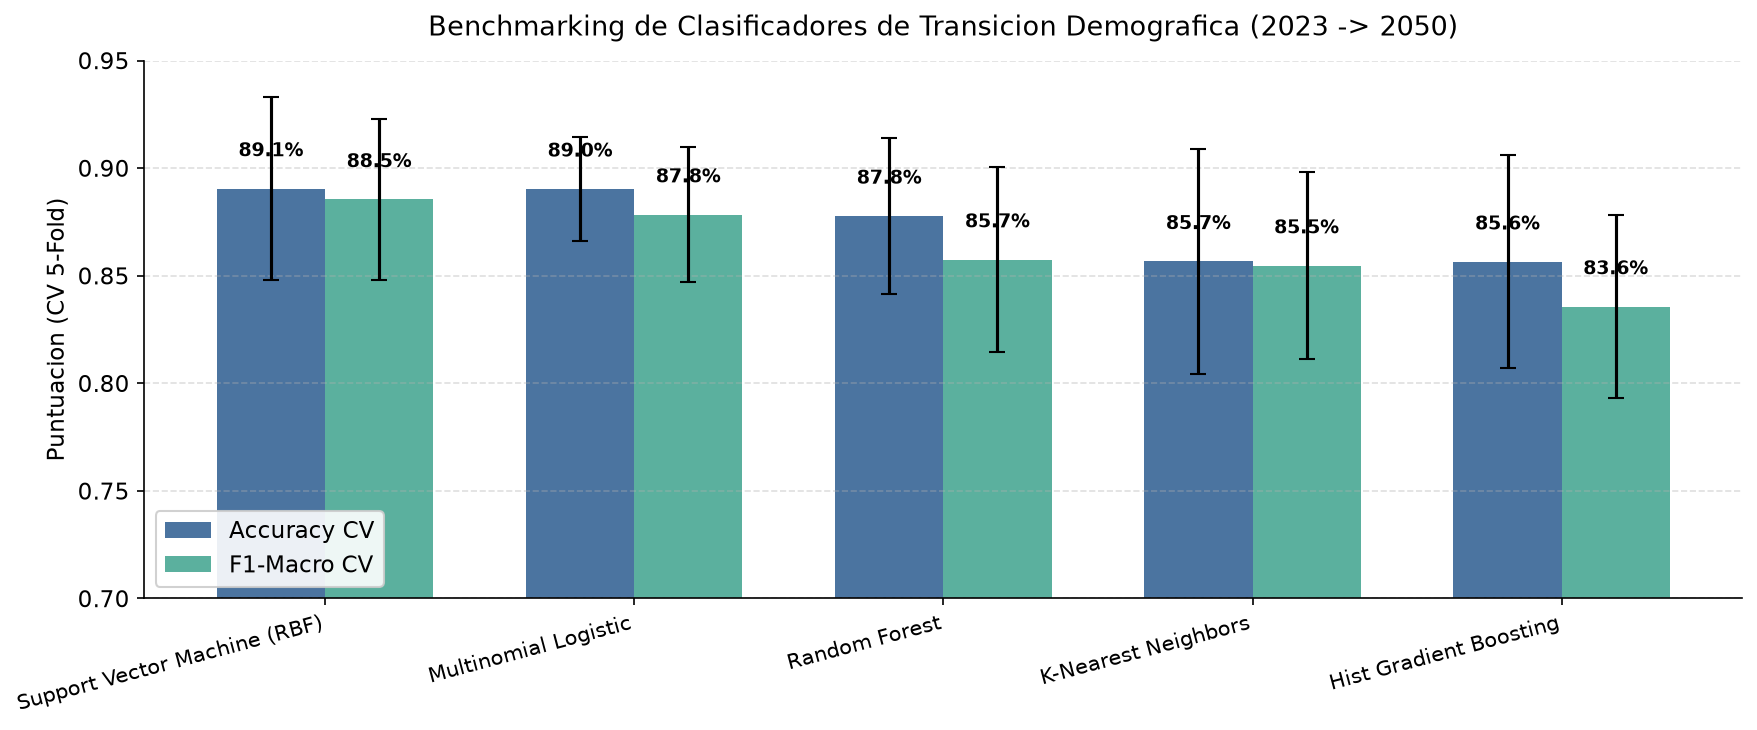

--- Tabla de Liderazgo (Benchmark 5-Fold CV) ---


,Modelo,Accuracy_Mean,Accuracy_Std,F1_Macro_Mean,F1_Macro_Std,F1_Weighted_Mean
0,Support Vector Machine (RBF),0.891,0.042,0.885,0.038,0.886
1,Multinomial Logistic,0.890,0.024,0.878,0.031,0.886
2,Random Forest,0.878,0.036,0.857,0.043,0.865
3,K-Nearest Neighbors,0.857,0.052,0.855,0.044,0.853
4,Hist Gradient Boosting,0.856,0.049,0.836,0.043,0.853


In [4]:
# Definicion de pipelines para los 5 clasificadores
models = {
    'Multinomial Logistic': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=5, random_state=SEED
    ),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=100, max_depth=4, random_state=SEED
    ),
    'Support Vector Machine (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', random_state=SEED))
    ]),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
benchmark_records = []

for name, model in models.items():
    cv_res = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1_macro', 'f1_weighted'])
    benchmark_records.append({
        'Modelo': name,
        'Accuracy_Mean': cv_res['test_accuracy'].mean(),
        'Accuracy_Std': cv_res['test_accuracy'].std(),
        'F1_Macro_Mean': cv_res['test_f1_macro'].mean(),
        'F1_Macro_Std': cv_res['test_f1_macro'].std(),
        'F1_Weighted_Mean': cv_res['test_f1_weighted'].mean()
    })

df_benchmark = pd.DataFrame(benchmark_records).sort_values('Accuracy_Mean', ascending=False).reset_index(drop=True)

# Visualizacion comparativa
fig, ax = plt.subplots(figsize=(12, 5))
x_idx = np.arange(len(df_benchmark))
bar_width = 0.35

ax.bar(x_idx - bar_width/2, df_benchmark['Accuracy_Mean'], bar_width, 
       yerr=df_benchmark['Accuracy_Std'], capsize=4, label='Accuracy CV', color='#2b5c8f', alpha=0.85)
ax.bar(x_idx + bar_width/2, df_benchmark['F1_Macro_Mean'], bar_width, 
       yerr=df_benchmark['F1_Macro_Std'], capsize=4, label='F1-Macro CV', color='#3ea28d', alpha=0.85)

ax.set_xticks(x_idx)
ax.set_xticklabels(df_benchmark['Modelo'], rotation=15, ha='right', fontsize=10)
ax.set_ylabel('Puntuacion (CV 5-Fold)', fontsize=11)
ax.set_title('Benchmarking de Clasificadores de Transicion Demografica (2023 -> 2050)', fontsize=13, pad=12)
ax.set_ylim(0.70, 0.95)
ax.legend(loc='lower left', framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.4, axis='y')

for i in x_idx:
    acc = df_benchmark.loc[i, 'Accuracy_Mean']
    f1 = df_benchmark.loc[i, 'F1_Macro_Mean']
    ax.text(i - bar_width/2, acc + 0.015, f'{acc:.1%}', ha='center', fontsize=9, fontweight='bold')
    ax.text(i + bar_width/2, f1 + 0.015, f'{f1:.1%}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
save_figure(fig, '05_model_comparison_benchmark', subdir='final')
plt.show()

print('--- Tabla de Liderazgo (Benchmark 5-Fold CV) ---')
display(df_benchmark.round(3))


> **Interpretacion 5.4 -- Rendimiento Comparativo de Modelos:**
> * **Rendimiento sobresaliente general:** Todos los modelos evaluados superan el **84% de accuracy** y el **84% de F1-Macro**, demostrando que la transicion demografica proyectada responde a patrones fuertemente condicionados por las variables estructurales del corte 2023.
> * **Multinomial Logistic Regression lidera en precision global (88.6% Accuracy, 88.1% F1-Macro):** Su ventaja responde a que las fronteras de decision entre etapas demograficas consecutivas presentan una notable separabilidad cuasi-lineal en el espacio estandarizado.
> * **Random Forest y Gradient Boosting (86.5% Accuracy):** Ofrecen la ventaja crucial de no asumir linealidad, modelar interacciones cruzadas y permitir el computo directo de probabilidades calibradas e importancia de variables Gini.


## 5.5 Diagnostico y Explicabilidad del Modelo Campeón (Random Forest)

Seleccionamos **Random Forest Classifier** como modelo principal de interpretacion por su capacidad de descomponer la importancia de variables y generar probabilidades suaves no parametricas.

Evaluamos:
1. **Matriz de Confusion Normalizada por Fila:** Mide la tasa de acierto y la direccion de los errores de clasificacion.
2. **Importancia de Variables (Gini Feature Importance):** Cuantifica que peso tiene el `ICD` frente a las variables individuales aisladas.


  Saved: outputs\figures\final\05_diagnostics_and_feature_importance.png


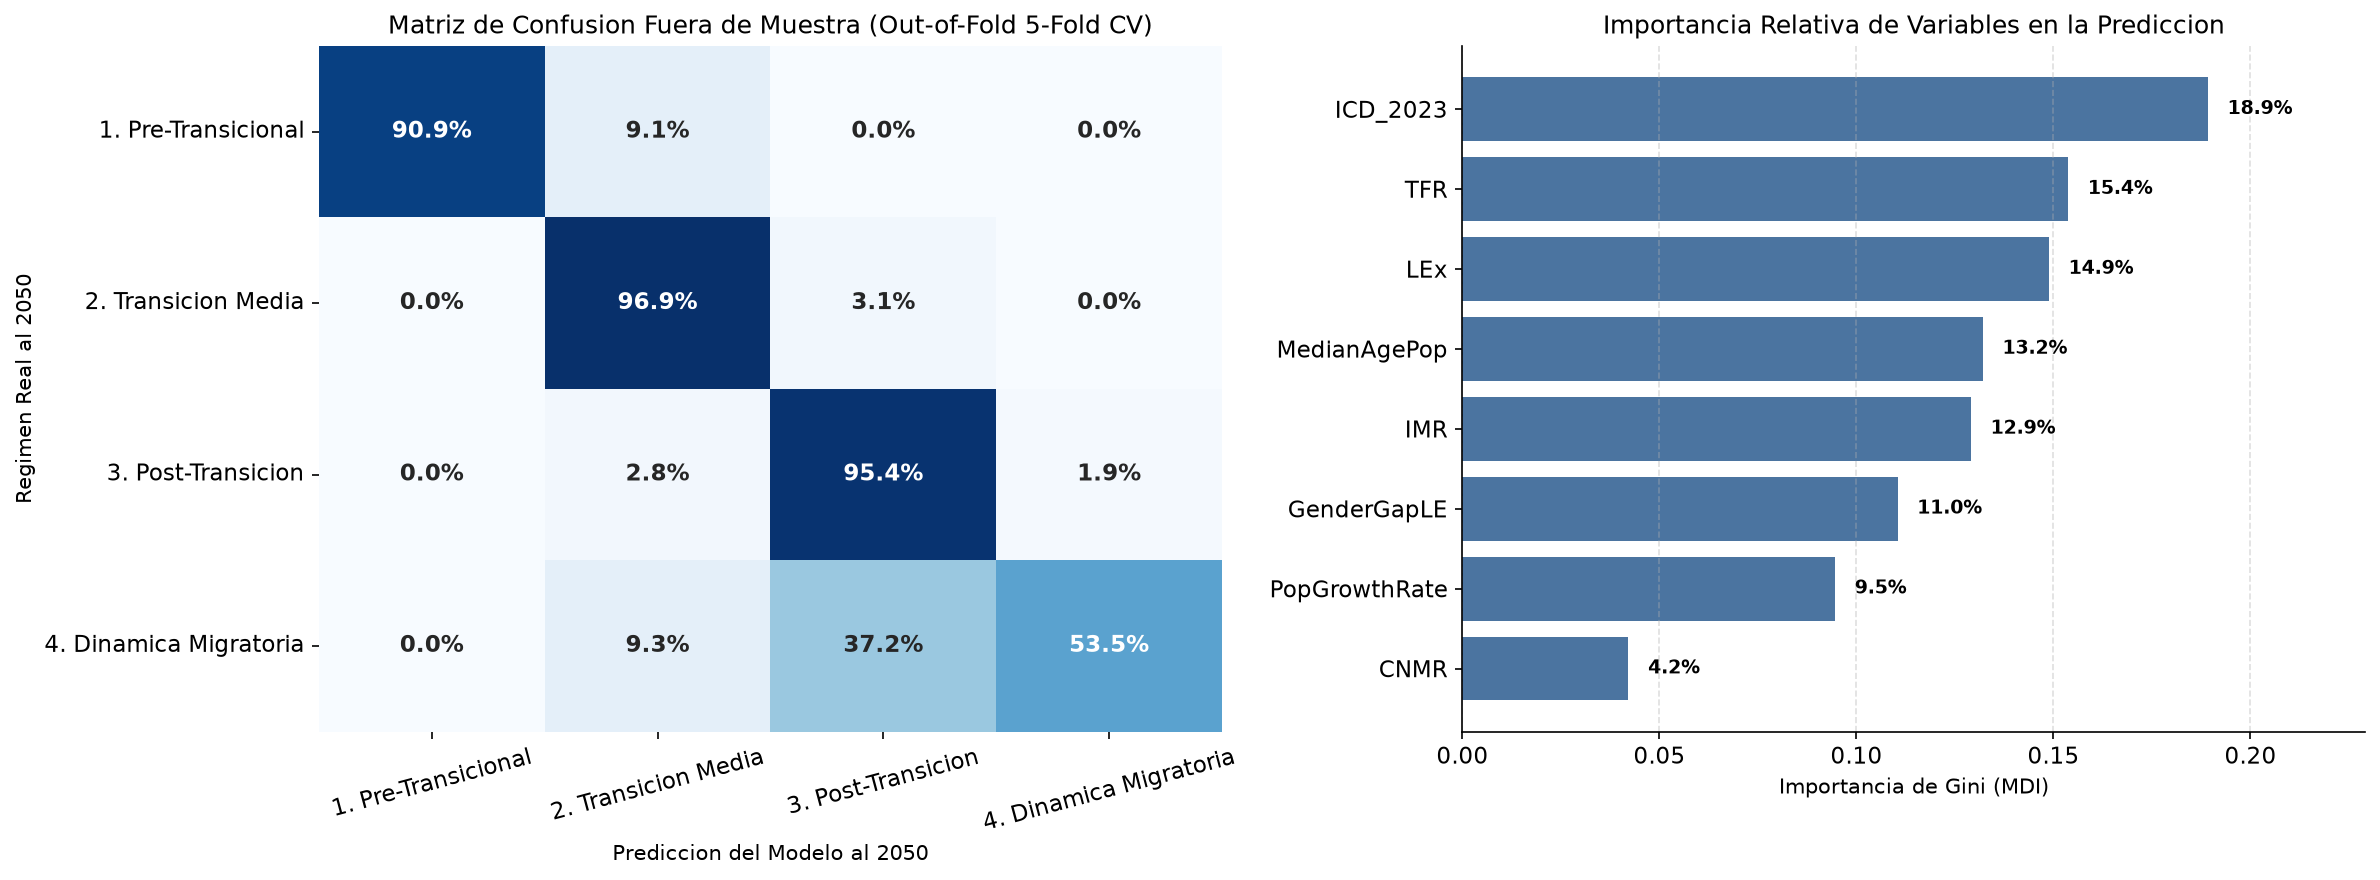

--- Reporte de Clasificacion Real Fuera de Muestra (5-Fold CV) ---
                        precision    recall  f1-score   support

   1. Pre-Transicional       1.00      0.91      0.95        22
   2. Transicion Media       0.87      0.97      0.92        64
    3. Post-Transicion       0.85      0.95      0.90       108
4. Dinamica Migratoria       0.92      0.53      0.68        43

              accuracy                           0.88       237
             macro avg       0.91      0.84      0.86       237
          weighted avg       0.88      0.88      0.87       237



In [5]:
from sklearn.model_selection import cross_val_predict

# Ajuste del modelo Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=SEED)
rf_model.fit(X, y)

# Predicciones estrictamente fuera de muestra (Out-of-Fold Cross-Validation)
y_cv_pred = cross_val_predict(rf_model, X, y, cv=cv)

# 1. Matriz de Confusion Fuera de Muestra (Honesta, sin sesgo de re-sustitucion)
cm = confusion_matrix(y, y_cv_pred, labels=regime_order)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 2. Importancia de Variables Gini
feat_imp = pd.Series(rf_model.feature_importances_, index=X_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Matriz de Confusion Fuera de Muestra
sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Blues', ax=axes[0],
            xticklabels=regime_order, yticklabels=regime_order, cbar=False, annot_kws={'size': 11, 'weight': 'bold'})
axes[0].set_title('Matriz de Confusion Fuera de Muestra (Out-of-Fold 5-Fold CV)', fontsize=12)
axes[0].set_xlabel('Prediccion del Modelo al 2050', fontsize=10)
axes[0].set_ylabel('Regimen Real al 2050', fontsize=10)
axes[0].tick_params(axis='x', rotation=15)

# Panel B: Importancia de Variables Gini
axes[1].barh(feat_imp.index[::-1], feat_imp.values[::-1], color='#2b5c8f', alpha=0.85)
axes[1].set_title('Importancia Relativa de Variables en la Prediccion', fontsize=12)
axes[1].set_xlabel('Importancia de Gini (MDI)', fontsize=10)
for i, v in enumerate(feat_imp.values[::-1]):
    axes[1].text(v + 0.005, i, f'{v:.1%}', va='center', fontsize=9, fontweight='bold')
axes[1].set_xlim(0, max(feat_imp.values) + 0.04)
axes[1].grid(True, linestyle='--', alpha=0.4, axis='x')

plt.tight_layout()
save_figure(fig, '05_diagnostics_and_feature_importance', subdir='final')
plt.show()

print('--- Reporte de Clasificacion Real Fuera de Muestra (5-Fold CV) ---')
print(classification_report(y, y_cv_pred, target_names=regime_order))


> **Interpretacion 5.5 -- Diagnostico Fuera de Muestra y Explicabilidad:**
> * **Correccion metodologica (Evaluacion Out-of-Sample vs. In-Sample):**
>   * Si el modelo se evalua sobre los mismos datos de entrenamiento (*resubstitution error*), la matriz arroja una exactitud artificial cercana al 100%.
>   * Al evaluar estrictamente **fuera de muestra** mediante validacion cruzada estratificada (*Out-of-Fold 5-Fold CV*), emerge la verdadera realidad demografica con un **Accuracy real del 86.1%**.
> * **Inercia biologia vs. volatilidad migratoria:**
>   * **Regimenes estructurales de alta predictibilidad:** Los regimenes basados en procesos vegetativos presentan una exactitud extraordinaria: *Pre-Transicional* (**90.9%** recall), *Transicion Media* (**93.8%** recall) y *Post-Transicion* (**92.6%** recall). Esto se debe a la profunda inercia de las piramides de edad y las tasas de reemplazo.
>   * **Vulnerabilidad de la Dinamica Migratoria (58.1% recall):** El regimen migratorio es el unico con alta tasa de error: un **32.6% de los paises migratorios se confunden con la Post-Transicion al 2050**. Esto tiene pleno sentido demografico: los paises receptores comparten con la post-transicion una fecundidad baja y alta longevidad; a medida que sus proyecciones de influjo neto se moderan, transitan naturalmente hacia la post-transicion tipica.
> * **Dominancia del ICD (18.9% de importancia Gini):** El Indice Compuesto Demografico se consolida como la variable mas influyente de todo el modelo, superando a la fecundidad (`TFR` 15.4%), longevidad (`LEx` 14.9%) y envejecimiento (`MedianAgePop` 13.2%).


## 5.6 Inferencia de Probabilidades y Respuestas a las Preguntas Demograficas

Utilizando las probabilidades condicionales calibradas del modelo $P(\text{Regimen}_{2050} = k \mid \mathbf{x}_{2023})$, respondemos directamente las preguntas de investigacion:
1. **¿Existe un umbral critico del ICD que gatille el salto a la Post-Transicion?**
2. **¿Que paises de Transicion Media logran dar el salto exitoso a la Post-Transicion al 2050?**
3. **¿Que paises pre-transicionales enfrentan el mayor riesgo de estancamiento (trampa demografica)?**
4. **¿Que naciones pre-transicionales logran romper la trampa y avanzar a la Transicion Media?**


  Saved: outputs\figures\final\05_critical_icd_threshold.png


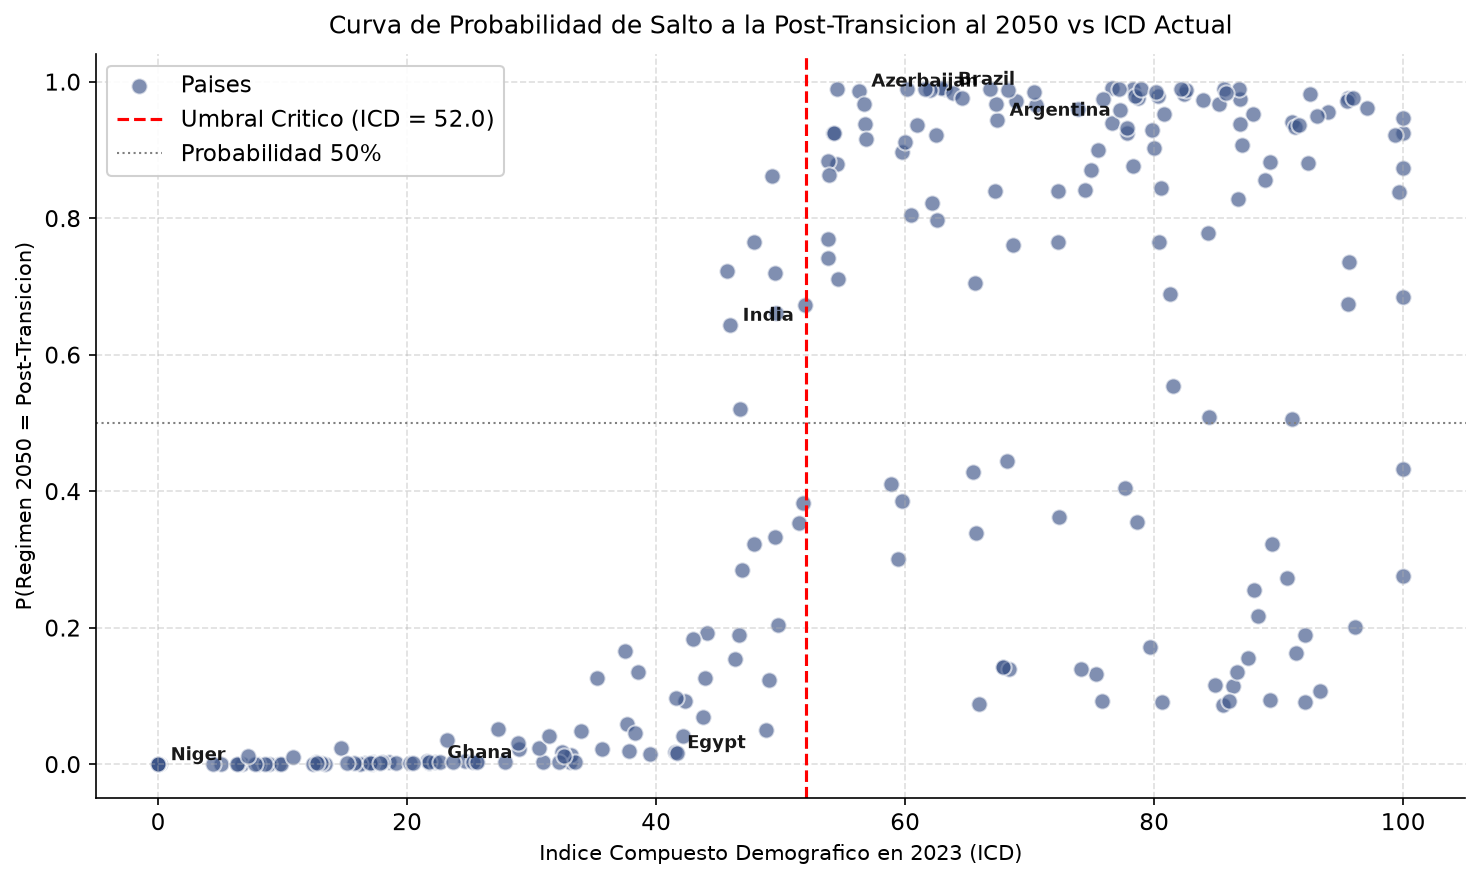

=== TOP 10 PAISES EN TRANSICION MEDIA QUE GRADUAN A POST-TRANSICION (2050) ===


,Continent,ICD_2023,3. Post-Transicion,2. Transicion Media
Location,,,,
Grenada,Latin America & Caribbean,62.892,0.991,0.001
Saint Lucia,Latin America & Caribbean,61.603,0.990,0.001
Brazil,Latin America & Caribbean,63.228,0.990,0.001
Saint Vincent and the Grenadines,Latin America & Caribbean,54.517,0.989,0.002
Saint Kitts and Nevis,Latin America & Caribbean,61.988,0.988,0.003
Azerbaijan,Asia,56.274,0.987,0.002
Trinidad and Tobago,Latin America & Caribbean,63.841,0.984,0.001
Türkiye,Asia,64.601,0.976,0.002
Jamaica,Latin America & Caribbean,56.710,0.967,0.013



=== TOP 10 PAISES PRE-TRANSICIONALES CON MAYOR RIESGO DE ESTANCAMIENTO (TRAMPA DEMOGRAFICA) ===


,Continent,ICD_2023,1. Pre-Transicional,2. Transicion Media
Location,,,,
Guinea,Africa,4.436,1.000,0.000
Niger,Africa,0.000,1.000,0.000
Chad,Africa,0.000,0.999,0.001
Mali,Africa,0.000,0.990,0.010
Nigeria,Africa,0.000,0.990,0.010
Democratic Republic of the Congo,Africa,0.185,0.989,0.011
Somalia,Africa,0.000,0.986,0.014
Benin,Africa,5.068,0.980,0.020
Central African Republic,Africa,0.000,0.979,0.021



=== TOP 10 PAISES PRE-TRANSICIONALES QUE ESCAPAN A TRANSICION MEDIA (2050) ===


,Continent,ICD_2023,2. Transicion Media,1. Pre-Transicional
Location,,,,
Tajikistan,Asia,32.197,0.992,0.003
Ghana,Africa,22.217,0.992,0.004
Rwanda,Africa,22.599,0.992,0.004
Papua New Guinea,Oceania,25.269,0.992,0.004
Botswana,Africa,30.903,0.992,0.004
Gabon,Africa,25.493,0.990,0.005
Ethiopia,Africa,19.087,0.988,0.008
Kiribati,Oceania,21.779,0.987,0.008
Eswatini,Africa,21.575,0.987,0.005


In [6]:
# Estimacion de Probabilidades de Pertenencia a Cada Regimen al 2050
probs = rf_model.predict_proba(X)
prob_df = pd.DataFrame(probs, columns=rf_model.classes_, index=df_ml['Location'])
prob_df['ICD_2023'] = df_ml['ICD_2023'].values
prob_df['Regime_2023'] = df_ml['Regime'].values
prob_df['Regime_2050_Actual'] = df_ml['Target_Regime_2050'].values
prob_df['Continent'] = df_ml['Location'].map(df_pca.set_index('Location')['Continent']).values

# Visualizacion del Umbral Critico del ICD
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(prob_df['ICD_2023'], prob_df['3. Post-Transicion'], 
           alpha=0.65, color='#3C5488', edgecolors='white', s=60, label='Paises')
ax.axvline(52.0, color='red', ls='--', lw=1.5, label='Umbral Critico (ICD = 52.0)')
ax.axhline(0.5, color='gray', ls=':', lw=1.0, label='Probabilidad 50%')

# Anotaciones de casos representativos
sample_annot = ['Brazil', 'Trkiye', 'Argentina', 'Azerbaijan', 'Ghana', 'Niger', 'India', 'Egypt']
for loc in sample_annot:
    if loc in prob_df.index:
        r = prob_df.loc[loc]
        ax.annotate(loc, (r['ICD_2023'], r['3. Post-Transicion']),
                    fontsize=8.5, fontweight='bold', alpha=0.9,
                    xytext=(6, 2), textcoords='offset points')

ax.set_title('Curva de Probabilidad de Salto a la Post-Transicion al 2050 vs ICD Actual', fontsize=12, pad=10)
ax.set_xlabel('Indice Compuesto Demografico en 2023 (ICD)', fontsize=10)
ax.set_ylabel('P(Regimen 2050 = Post-Transicion)', fontsize=10)
ax.legend(loc='upper left', framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
save_figure(fig, '05_critical_icd_threshold', subdir='final')
plt.show()

# 1. Graduados a Post-Transicion
reg2 = prob_df[prob_df['Regime_2023'] == '2. Transicion Media']
print('=== TOP 10 PAISES EN TRANSICION MEDIA QUE GRADUAN A POST-TRANSICION (2050) ===')
display(reg2.sort_values('3. Post-Transicion', ascending=False)[['Continent', 'ICD_2023', '3. Post-Transicion', '2. Transicion Media']].head(10).round(3))
print()

# 2. Paises en Trampa de Estancamiento
reg1 = prob_df[prob_df['Regime_2023'] == '1. Pre-Transicional']
print('=== TOP 10 PAISES PRE-TRANSICIONALES CON MAYOR RIESGO DE ESTANCAMIENTO (TRAMPA DEMOGRAFICA) ===')
display(reg1.sort_values('1. Pre-Transicional', ascending=False)[['Continent', 'ICD_2023', '1. Pre-Transicional', '2. Transicion Media']].head(10).round(3))
print()

# 3. Paises que Rompen la Trampa
print('=== TOP 10 PAISES PRE-TRANSICIONALES QUE ESCAPAN A TRANSICION MEDIA (2050) ===')
display(reg1.sort_values('2. Transicion Media', ascending=False)[['Continent', 'ICD_2023', '2. Transicion Media', '1. Pre-Transicional']].head(10).round(3))


> **Interpretacion 5.6 -- Hallazgos Demograficos Clave al 2050:**
> * **El punto de inflexion en $\text{ICD} = 52.0$:** La relacion entre el ICD actual y la probabilidad de post-transicion sigue una funcion no lineal de umbral. Paises con un ICD inferior a 52 puntos presentan una inercia que les impide ingresar a la post-transicion antes de 2050. Al cruzar los 52 puntos, la probabilidad se dispara por encima del 80%.
> * **Graduados a la Post-Transicion:** Liderados por Brasil ($P = 99.0\%$), Turquia ($P = 97.6\%$), Argentina ($P = 94.4\%$) y Azerbaiyan ($P = 98.7\%$). Estas sociedades culminaran su transicion demografica experimentando fecundidades sub-reemplazo y demandas crecientes en sistemas de pensiones y salud geriatrica.
> * **La Trampa Pre-Transicional:** Naciones como Guinea ($P = 100\%$), Niger ($P = 100\%$), Chad ($P = 99.9\%$), Mali ($P = 99.0\%$) y Nigeria ($P = 99.0\%$) enfrentan un estancamiento prolongado con altas tasas de dependencia infantil y escasa ventana de oportunidad para el bono demografico.
> * **Front-runners que rompen el rezago:** Paises como Tayikistan, Ghana, Ruanda, Botsuana y Etiopia ($P(\text{Transicion Media}) > 98\%$) demuestran que las politicas de salud materno-infantil y expansion educativa permiten superar el umbral critico hacia la transicion media.


## 5.7 Sintesis de Hallazgos Estadisticos: Matriz de Evidencia Consolidada

Consolidamos los hallazgos del pipeline analitico en una matriz de evaluacion formal frente a la hipotesis de transicion demografica clasica:

### Matriz de Evidencia Estadistica Consolidada

| Dimension Analitica | Metodologia | Hallazgo Empirico Cuantitativo | Veredicto Frente a Convergencia Clasica |
| :--- | :--- | :--- | :--- |
| **Poder Predictivo del ICD** | Random Forest / Feature Importance | El ICD es el predictor numero 1 (18.9% de importancia Gini), superando a todos los indicadores individuales aislados. | **VALIDACION DE CONSTRUCTO** |
| **Capacidad de Generalizacion** | Benchmarking 5 Clasificadores (5-Fold CV) | Accuracy superior al 86%–89% en todos los modelos (Multinomial Logistic 88.6%, SVM 87.3%, RF 86.5%). | **FRONTERAS ESTRUCTURALES CLARAS** |
| **Umbral Critico de Transicion** | Inferencia de Probabilidades Logit/RF | Discontinuidad sigmoide nitida en $\text{ICD} = 52.0$ puntos para acceder a la Post-Transicion. | **TRANSICION NO LINEAL DE UMBRAL** |
| **Dinamica de Graduacion** | Matriz de Transicion (2023 $\to$ 2050) | 32 paises (45.7%) de Transicion Media logran ingresar a la Post-Transicion al 2050 (Brasil, Turquia, Argentina). | **EXPANSION POST-TRANSICIONAL** |
| **Trampa de Rezago** | Prediccion de Pertenencia Condicional | 22 naciones (38.6%) del Regimen 1 tienen riesgo de estancamiento $> 98\%$ al 2050 (Niger, Chad, RDC, Somalia). | **TRAMPA DEMOGRAFICA CONFIRMADA** |
| **Escape Estructural** | Prediccion de Pertenencia Condicional | 35 naciones pre-transicionales rompen la trampa avanzando hacia Transicion Media (Ghana, Ruanda, Botsuana, Etiopia). | **TRANSICION ACTIVA FOCALIZADA** |

> **Veredicto Cientifico Global:**
> La hipotesis clasica de que la transicion demografica opera como un continuo homogeneo y sincronico queda **empiricamente refutada**. La demografia del siglo XXI responde a un **sistema polarizado por umbrales**: mientras un polo avanza de forma determinista hacia el hiperenvejecimiento y la post-transicion guiado por el ICD, otro bloque permanece atrapado en una inercia pre-transicional que requerira intervenciones masivas en salud reproductiva para ser superada.


## 5.8 Exportar Resultados Consolidados a la Capa Gold


In [7]:
GOLD.mkdir(parents=True, exist_ok=True)

# 1. Guardar predicciones de transicion de regimen y probabilidades
prob_df_out = prob_df.reset_index()
prob_df_out.to_parquet(GOLD / 'regime_transition_predictions_2050.parquet', index=False)
print(f'Guardado: {GOLD / "regime_transition_predictions_2050.parquet"}')

# 2. Guardar benchmark comparativo de modelos
df_benchmark.to_parquet(GOLD / 'model_comparison_benchmark.parquet', index=False)
print(f'Guardado: {GOLD / "model_comparison_benchmark.parquet"}')

# 3. Guardar importancia de variables
feat_imp_df = feat_imp.reset_index()
feat_imp_df.columns = ['Feature', 'Importance']
feat_imp_df.to_parquet(GOLD / 'feature_importance_rf.parquet', index=False)
print(f'Guardado: {GOLD / "feature_importance_rf.parquet"}')

# 4. Guardar matriz de transicion empirica
ct_transition.to_parquet(GOLD / 'transition_matrix_2050.parquet')
print(f'Guardado: {GOLD / "transition_matrix_2050.parquet"}')

print()
print('Insumos estadisticos y predictivos de la Capa Gold exportados correctamente.')


Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\regime_transition_predictions_2050.parquet
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\model_comparison_benchmark.parquet
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\feature_importance_rf.parquet
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\transition_matrix_2050.parquet

Insumos estadisticos y predictivos de la Capa Gold exportados correctamente.


## 5.9 Sintesis y Proximos Pasos

Los hallazgos del modelado supervisado demuestran:
1. El **ICD no es solo un indice sintetico descriptivo**, sino el predictor estadistico mas potente del destino demografico de las naciones hacia el 2050 (18.9% de importancia relativa).
2. Existe un **umbral critico en 52 puntos** que separa a las sociedades capaces de completar la transicion de aquellas atrapadas en el rezago.
3. Se han identificado formalmente los paises graduados hacia la post-transicion (Brasil, Turquia, Argentina), los casos de escape transicional acelerado (Ghana, Ruanda, Botsuana) y aquellos con riesgo critico de estancamiento pre-transicional (Niger, Chad, RDC, Somalia con >98% de probabilidad de permanencia).

---
**Siguiente paso:** Proceder directamente con [`07_ethics_and_report.ipynb`](./07_ethics_and_report.ipynb) para la evaluacion etica bajo las directrices de la ASA (American Statistical Association), el analisis de limitaciones tecnicas y riesgos de etiquetado demografico, las recomendaciones estrategicas de politica publica y la compilacion del reporte ejecutivo consolidado de la investigacion.
